In [22]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Support running from either the project root or notebooks folder.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "raw" / "Online Retail.xlsx"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df_raw = pd.read_excel(
    DATA_PATH,
    dtype={
        "InvoiceNo": "string",
        "StockCode": "string",
        "CustomerID": "string",
    },
)

print(f"Rows: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]}")
df_raw.head()

Rows: 541,909
Columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [23]:
df_raw.info()

quality_report = pd.DataFrame({
    "data_type": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isna().sum(),
    "missing_pct": df_raw.isna().mean().mul(100).round(2),
    "unique_values": df_raw.nunique(),
})

display(quality_report)
print(f"Exact duplicate rows: {df_raw.duplicated().sum():,}")

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  string        
 1   StockCode    541909 non-null  string        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  string        
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), object(1), str(1), string(3)
memory usage: 33.1+ MB


,data_type,missing_count,missing_pct,unique_values
InvoiceNo,string,0,0.00,25900
StockCode,string,0,0.00,4070
Description,object,1454,0.27,4223
Quantity,int64,0,0.00,722
InvoiceDate,datetime64[us],0,0.00,23260
UnitPrice,float64,0,0.00,1630
CustomerID,string,135080,24.93,4372
Country,str,0,0.00,38


Exact duplicate rows: 5,268


## Initial Data Quality Findings

- The dataset contains 541,909 transaction lines and 8 columns.
- CustomerID is missing in 24.93% of rows. These records remain useful
  for sales analysis but cannot support customer-level analysis.
- Description is missing in 0.27% of rows.
- There are 5,268 exact duplicate rows. Without a unique line identifier,
  these are potential duplicates rather than confirmed errors.
- Next, inspect cancellations, negative quantities, nonpositive prices,
  and the observation period before creating analysis datasets.

In [24]:
# Work on a copy so the original dataset stays available.
df = df_raw.copy()

df["InvoiceNo"] = df["InvoiceNo"].str.strip()
df["StockCode"] = df["StockCode"].str.strip()
df["CustomerID"] = df["CustomerID"].str.strip()
df["Description"] = (
    df["Description"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

df["is_cancellation"] = (
    df["InvoiceNo"].str.upper().str.startswith("C", na=False)
)

# Mark repeated copies after the first occurrence.
df["is_duplicate_candidate"] = df_raw.duplicated()

audit = pd.Series({
    "Total transaction lines": len(df),
    "Cancellation lines": int(df["is_cancellation"].sum()),
    "Negative quantity lines": int(df["Quantity"].lt(0).sum()),
    "Zero quantity lines": int(df["Quantity"].eq(0).sum()),
    "Zero price lines": int(df["UnitPrice"].eq(0).sum()),
    "Negative price lines": int(df["UnitPrice"].lt(0).sum()),
    "Missing customer IDs": int(df["CustomerID"].isna().sum()),
    "Duplicate candidates": int(df["is_duplicate_candidate"].sum()),
})

display(audit.to_frame("Count"))

print("First transaction:", df["InvoiceDate"].min())
print("Last transaction:", df["InvoiceDate"].max())

display(
    pd.crosstab(
        df["is_cancellation"],
        df["Quantity"].lt(0),
        rownames=["Cancellation invoice"],
        colnames=["Negative quantity"],
    )
)

display(
    df.loc[
        df["Quantity"].le(0) | df["UnitPrice"].le(0)
    ].head(10)
)

,Count
Total transaction lines,541909
Cancellation lines,9288
Negative quantity lines,10624
Zero quantity lines,0
Zero price lines,2515
Negative price lines,2
Missing customer IDs,135080
Duplicate candidates,5268


First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00


Negative quantity,False,True
Cancellation invoice,,
False,531285,1336
True,0,9288


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,is_cancellation,is_duplicate_candidate
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom,True,False
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311,United Kingdom,True,False
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom,True,False
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom,True,False
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom,True,False
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom,True,False
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548,United Kingdom,True,False
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom,True,False
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548,United Kingdom,True,False
622,536414,22139,<NA>,56,2010-12-01 11:52:00,0.00,<NA>,United Kingdom,False,False


## Analysis Dataset Definitions

- Positive sales: non-cancellation lines with quantity and unit price
  greater than zero.
- Customer analysis: positive sales with a known CustomerID.
- Cancellation and adjustment records remain available separately.
- Duplicate candidates are retained initially; their effect will be
  measured before deciding whether to exclude them.
- Sales value is Quantity × UnitPrice in GBP. It is not profit or
  net revenue after cancellations.
- December 2011 is incomplete and should be flagged in monthly charts.

In [25]:
positive_sales_mask = (
    ~df["is_cancellation"]
    & df["Quantity"].gt(0)
    & df["UnitPrice"].gt(0)
)

sales = df.loc[positive_sales_mask].copy()
sales["sales_value"] = sales["Quantity"] * sales["UnitPrice"]
sales["month"] = sales["InvoiceDate"].dt.to_period("M")
sales["weekday"] = sales["InvoiceDate"].dt.day_name()
sales["hour"] = sales["InvoiceDate"].dt.hour

customer_sales = sales.loc[sales["CustomerID"].notna()].copy()

# Retain excluded records for separate investigation.
excluded_records = df.loc[~positive_sales_mask].copy()

assert len(sales) + len(excluded_records) == len(df)

summary = pd.Series({
    "Positive sales lines": len(sales),
    "Excluded lines": len(excluded_records),
    "Distinct sales invoices": sales["InvoiceNo"].nunique(),
    "Identified customers": customer_sales["CustomerID"].nunique(),
    "Sales value (GBP)": round(sales["sales_value"].sum(), 2),
})

display(summary.to_frame("Value"))

# Compare totals with and without potential duplicate copies.
sales_without_candidates = sales.loc[
    ~sales["is_duplicate_candidate"]
]

comparison = pd.DataFrame({
    "Policy": ["Retain duplicate candidates", "Exclude duplicate candidates"],
    "Sales lines": [len(sales), len(sales_without_candidates)],
    "Sales value (GBP)": [
        sales["sales_value"].sum(),
        sales_without_candidates["sales_value"].sum(),
    ],
})

display(comparison.round(2))

duplicate_value = (
    sales["sales_value"].sum()
    - sales_without_candidates["sales_value"].sum()
)

print(
    "Duplicate candidates' share of positive sales value: "
    f"{duplicate_value / sales['sales_value'].sum():.2%}"
)

,Value
Positive sales lines,530104.00
Excluded lines,11805.00
Distinct sales invoices,19960.00
Identified customers,4338.00
Sales value (GBP),10666684.54


,Policy,Sales lines,Sales value (GBP)
0,Retain duplicate candidates,530104,10666684.54
1,Exclude duplicate candidates,524878,10642110.80


Duplicate candidates' share of positive sales value: 0.23%


## Monthly Sales Trends

Monthly sales value includes positive-quantity, positive-price,
non-cancellation lines, with duplicate candidates retained.

December 2011 contains observations only through December 9.
Its total is not directly comparable with full months.

,sales_value,invoices,units,average_invoice_value
month,,,,
2010-12,823746.14,1559,359239,528.38
2011-01,691364.56,1086,387785,636.62
2011-02,523631.89,1100,283555,476.03
2011-03,717639.36,1454,377526,493.56
2011-04,537808.62,1246,308815,431.63
2011-05,770536.02,1681,395738,458.38
2011-06,761739.90,1533,389213,496.89
2011-07,719221.19,1475,401759,487.61
2011-08,759138.38,1361,421770,557.78


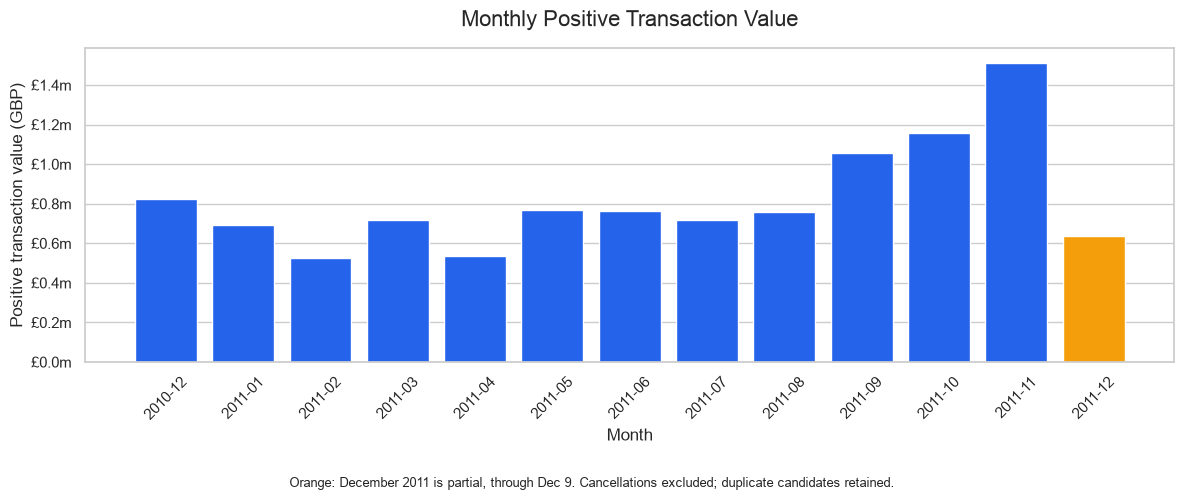

Highest full-month positive transaction value: 2011-11 — £1,509,496.33


In [26]:
from matplotlib.ticker import FuncFormatter

FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

monthly = (
    sales.groupby("month")
    .agg(
        sales_value=("sales_value", "sum"),
        invoices=("InvoiceNo", "nunique"),
        units=("Quantity", "sum"),
    )
    .sort_index()
)

monthly["average_invoice_value"] = (
    monthly["sales_value"] / monthly["invoices"]
)

display(monthly.round(2))

labels = monthly.index.astype(str)
partial_month = pd.Period("2011-12", freq="M")

colors = [
    "#f59e0b" if month == partial_month else "#2563eb"
    for month in monthly.index
]

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(labels, monthly["sales_value"], color=colors)
ax.set_title(
    "Monthly Positive Transaction Value",
    fontsize=16,
    pad=16,
)
ax.set_xlabel("Month")
ax.set_ylabel("Positive transaction value (GBP)")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"£{value / 1_000_000:.1f}m")
)

ax.tick_params(axis="x", rotation=45)
ax.grid(axis="x", visible=False)

fig.text(
    0.5,
    0.01,
    "Orange: December 2011 is partial, through Dec 9. "
    "Cancellations excluded; duplicate candidates retained.",
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=(0, 0.06, 1, 1))

fig.savefig(
    FIGURES / "monthly_sales.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

full_months = monthly.loc[
    (monthly.index >= pd.Period("2010-12", freq="M"))
    & (monthly.index <= pd.Period("2011-11", freq="M"))
]

peak_month = full_months["sales_value"].idxmax()
peak_value = full_months.loc[peak_month, "sales_value"]

print(
    f"Highest full-month positive transaction value: "
    f"{peak_month} — £{peak_value:,.2f}"
)

### Monthly Findings

- November 2011 recorded the highest full-month positive sales value:
  £1,509,496.33.
- Sales increased from September through November 2011.
- This pattern alone does not establish recurring seasonality or its cause.
- December 2011 is incomplete and cannot be compared directly with
  full-month totals.

,sales_value,invoices,identified_customers,sales_share_pct
Country,,,,
United Kingdom,9025222.08,18019,3920,84.61
Netherlands,285446.34,94,9,2.68
EIRE,283453.96,288,3,2.66
Germany,228867.14,457,94,2.15
France,209715.11,392,87,1.97
Australia,138521.31,57,9,1.30
Spain,61577.11,90,30,0.58
Switzerland,57089.90,54,21,0.54
Belgium,41196.34,98,25,0.39


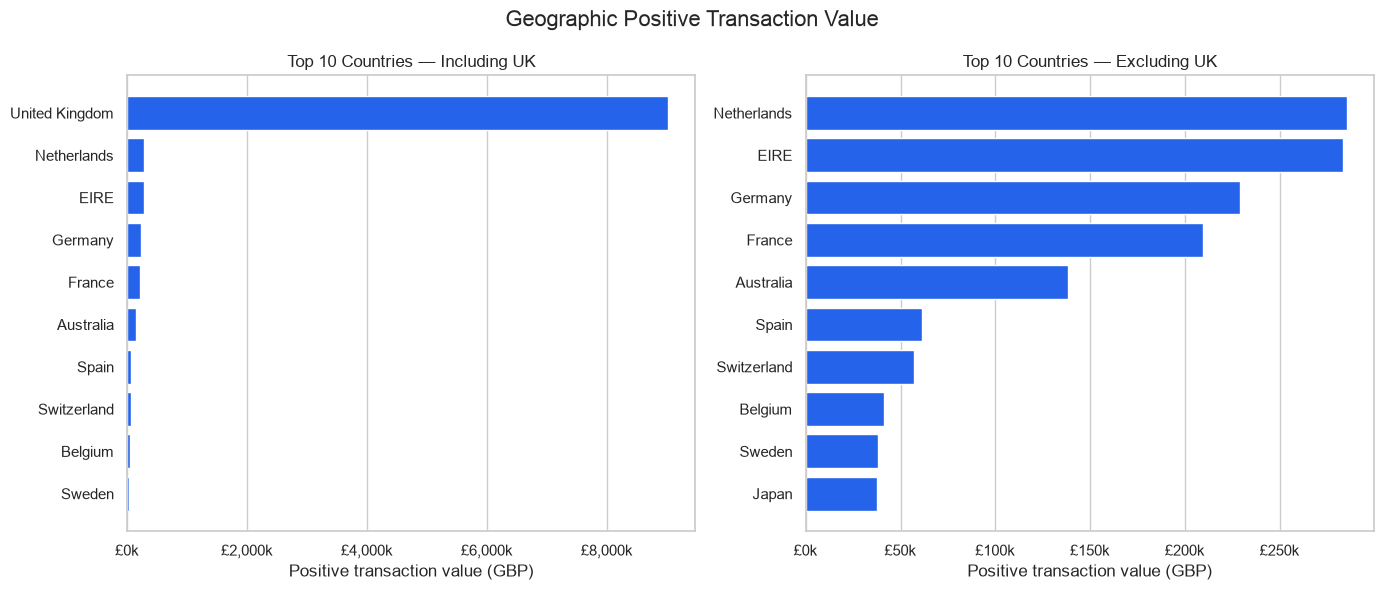

UK share of positive transaction value: 84.61%


In [27]:
country_summary = (
    sales.groupby("Country")
    .agg(
        sales_value=("sales_value", "sum"),
        invoices=("InvoiceNo", "nunique"),
        identified_customers=("CustomerID", "nunique"),
    )
    .sort_values("sales_value", ascending=False)
)

country_summary["sales_share_pct"] = (
    country_summary["sales_value"]
    / sales["sales_value"].sum()
    * 100
)

display(country_summary.head(10).round(2))

international = country_summary.drop(
    index="United Kingdom",
    errors="ignore",
).head(10)

fig, axes = plt.subplots(ncols=2, figsize=(14, 6))

panels = [
    (
        country_summary.head(10),
        "Top 10 Countries — Including UK",
    ),
    (
        international,
        "Top 10 Countries — Excluding UK",
    ),
]

for ax, (table, title) in zip(axes, panels):
    ordered = table.sort_values("sales_value")

    ax.barh(
        ordered.index,
        ordered["sales_value"],
        color="#2563eb",
    )

    ax.set_title(title)
    ax.set_xlabel("Positive transaction value (GBP)")

    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda value, _: f"£{value / 1_000:,.0f}k")
    )

    ax.grid(axis="y", visible=False)

fig.suptitle(
    "Geographic Positive Transaction Value",
    fontsize=16,
)

fig.tight_layout()

fig.savefig(
    FIGURES / "country_sales.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

uk_share = country_summary.loc[
    "United Kingdom",
    "sales_share_pct",
]

print(f"UK share of positive transaction value: {uk_share:.2f}%")

### Geographic Findings

- The UK contributes 84.61% of positive sales value.
- The Netherlands is the largest international market by sales value,
  followed by EIRE, Germany, and France.
- The Netherlands has only 9 identified customers in this dataset.
  High sales value does not necessarily indicate a broad customer base.
- These results describe this retailer, not the overall retail market.

## Product and Stock Code Analysis

Aggregate by StockCode because descriptions can vary for the same code.
Inspect leading codes for non-merchandise entries before interpreting
the ranking as product performance.

In [28]:
# Use the most frequent description as a display label for each code.
description_counts = (
    sales.dropna(subset=["Description"])
    .groupby(["StockCode", "Description"])
    .size()
    .reset_index(name="line_count")
)

product_labels = (
    description_counts
    .sort_values(
        ["StockCode", "line_count", "Description"],
        ascending=[True, False, True],
    )
    .drop_duplicates("StockCode")
    .set_index("StockCode")["Description"]
)

product_summary = (
    sales.groupby("StockCode")
    .agg(
        sales_value=("sales_value", "sum"),
        units=("Quantity", "sum"),
        invoices=("InvoiceNo", "nunique"),
    )
    .join(product_labels)
    .sort_values("sales_value", ascending=False)
)

product_summary["Description"] = (
    product_summary["Description"].fillna("Unknown description")
)

display(product_summary.head(20).round(2))

# Inspect high-value individual lines for possible outliers.
display(
    sales.nlargest(10, "sales_value")[
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "UnitPrice",
            "sales_value",
        ]
    ]
)

,sales_value,units,invoices,Description
StockCode,,,,
DOT,206248.77,706,706,DOTCOM POSTAGE
22423,174484.74,13879,1988,REGENCY CAKESTAND 3 TIER
23843,168469.60,80995,1,"PAPER CRAFT , LITTLE BIRDIE"
85123A,104518.80,37660,2198,WHITE HANGING HEART T-LIGHT HOLDER
47566,99504.33,18295,1685,PARTY BUNTING
85099B,94340.05,48474,2089,JUMBO BAG RED RETROSPOT
23166,81700.92,78033,247,MEDIUM CERAMIC TOP STORAGE JAR
M,78110.27,7224,289,Manual
POST,78101.88,3150,1126,POSTAGE


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,sales_value
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33
299982,A563185,B,Adjust bad debt,1,11062.06,11062.06
173382,551697,POST,POSTAGE,1,8142.75,8142.75
348325,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
421601,573003,23084,RABBIT NIGHT LIGHT,2400,2.08,4992.00


### Transaction Scope and Unusual Records

Positive transaction totals include non-merchandise codes such as
DOT, POST, M, AMAZONFEE, and B. Earlier monthly and country totals
therefore describe positive transaction value.

These observed codes are excluded from the merchandise ranking.
This exclusion list is provisional, not a complete product taxonomy.

Large product transactions are retained pending investigation.
Cancellation records will be inspected for the same stock codes;
matching a code alone does not prove that a sale was reversed.

In [29]:
# Codes observed in the inspection as fees or accounting entries.
non_merchandise_codes = {"DOT", "POST", "M", "AMAZONFEE", "B"}

merchandise = sales.loc[
    ~sales["StockCode"].isin(non_merchandise_codes)
].copy()

excluded_charges = sales.loc[
    sales["StockCode"].isin(non_merchandise_codes)
]

print(
    "Positive value excluded by the provisional code list: "
    f"£{excluded_charges['sales_value'].sum():,.2f}"
)

# Inspect both positive and negative records for unusual product codes.
review_codes = ["23843", "23166"]

review = df.loc[
    df["StockCode"].isin(review_codes)
    & (df["Quantity"].abs() >= 10_000)
].copy()

review["signed_value"] = review["Quantity"] * review["UnitPrice"]

print("\nLarge product lines and potential reversal records:")
print(
    review[
        [
            "InvoiceNo",
            "InvoiceDate",
            "CustomerID",
            "StockCode",
            "Quantity",
            "UnitPrice",
            "signed_value",
            "is_cancellation",
        ]
    ]
    .sort_values(["StockCode", "InvoiceDate"])
    .to_string(index=False)
)

# Provisional merchandise ranking; unusual lines remain included.
merchandise_summary = (
    merchandise.groupby("StockCode")
    .agg(
        sales_value=("sales_value", "sum"),
        units=("Quantity", "sum"),
        invoices=("InvoiceNo", "nunique"),
    )
    .join(product_labels)
    .sort_values("sales_value", ascending=False)
)

display(merchandise_summary.head(10).round(2))

Positive value excluded by the provisional code list: £387,284.07

Large product lines and potential reversal records:
InvoiceNo         InvoiceDate CustomerID StockCode  Quantity  UnitPrice  signed_value  is_cancellation
   541431 2011-01-18 10:01:00      12346     23166     74215       1.04       77183.6            False
  C541433 2011-01-18 10:17:00      12346     23166    -74215       1.04      -77183.6             True
   581483 2011-12-09 09:15:00      16446     23843     80995       2.08      168469.6            False
  C581484 2011-12-09 09:27:00      16446     23843    -80995       2.08     -168469.6             True


,sales_value,units,invoices,Description
StockCode,,,,
22423,174484.74,13879,1988,REGENCY CAKESTAND 3 TIER
23843,168469.60,80995,1,"PAPER CRAFT , LITTLE BIRDIE"
85123A,104518.80,37660,2198,WHITE HANGING HEART T-LIGHT HOLDER
47566,99504.33,18295,1685,PARTY BUNTING
85099B,94340.05,48474,2089,JUMBO BAG RED RETROSPOT
23166,81700.92,78033,247,MEDIUM CERAMIC TOP STORAGE JAR
23084,66964.99,30788,994,RABBIT NIGHT LIGHT
22086,64952.29,19355,1160,PAPER CHAIN KIT 50'S CHRISTMAS
84879,59094.93,36461,1455,ASSORTED COLOUR BIRD ORNAMENT


### Reversal Findings

Two unusually large positive lines have matching cancellation entries
for the same customer, stock code, price, and opposite quantity,
minutes later.

Positive-only totals include these original entries. A signed-value
comparison includes negative quantities and shows their offsetting effect.

Signed transaction value is not profit. Negative entries may include
cancellations or adjustments, and the non-merchandise exclusion list
remains provisional.

,Description,sales_value,signed_value
StockCode,,,
23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,4221.28
23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,0.00


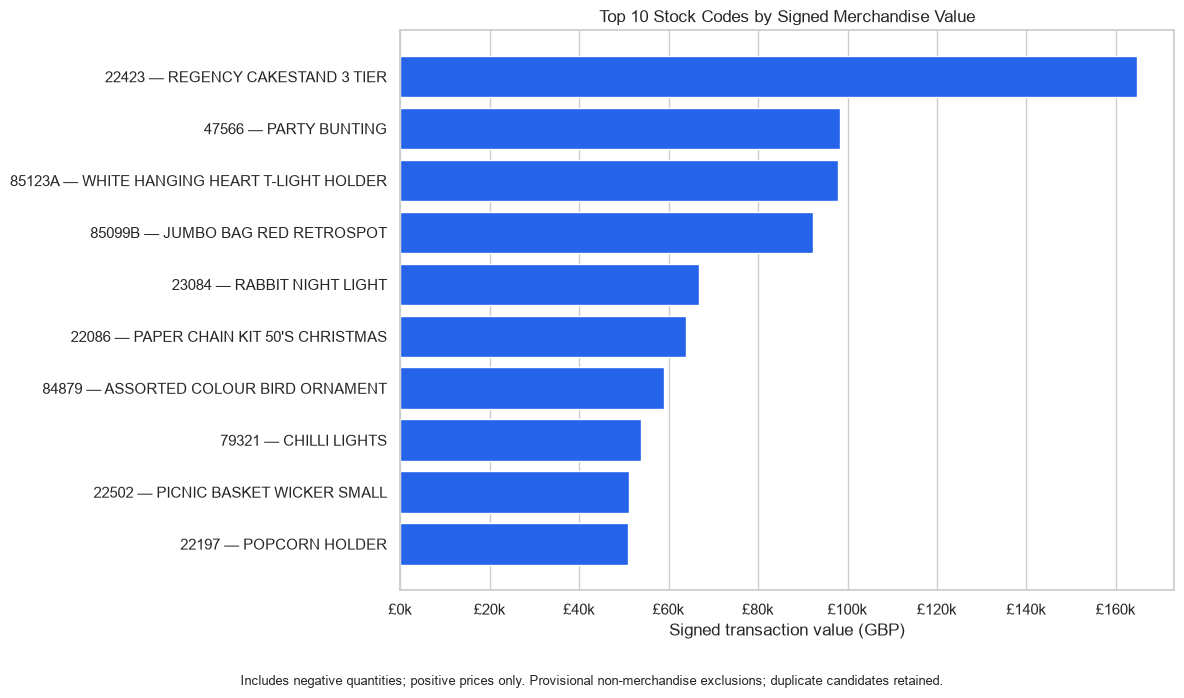

In [30]:
# Include positive and negative quantities at positive unit prices.
merchandise_ledger = df.loc[
    ~df["StockCode"].isin(non_merchandise_codes)
    & df["UnitPrice"].gt(0)
].copy()

merchandise_ledger["signed_value"] = (
    merchandise_ledger["Quantity"]
    * merchandise_ledger["UnitPrice"]
)

signed_products = (
    merchandise_ledger.groupby("StockCode")
    .agg(signed_value=("signed_value", "sum"))
)

product_comparison = (
    merchandise_summary
    .join(signed_products, how="outer")
)

product_comparison["Description"] = (
    product_comparison.index.to_series()
    .map(product_labels)
    .fillna("Unknown description")
)

product_comparison[["sales_value", "signed_value"]] = (
    product_comparison[["sales_value", "signed_value"]].fillna(0)
)

display(
    product_comparison.loc[
        ["23166", "23843"],
        ["Description", "sales_value", "signed_value"],
    ].round(2)
)

top_products = (
    product_comparison
    .nlargest(10, "signed_value")
    .sort_values("signed_value")
)

labels = [
    f"{code} — {description}"
    for code, description in zip(
        top_products.index,
        top_products["Description"],
    )
]

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(labels, top_products["signed_value"], color="#2563eb")
ax.set_title("Top 10 Stock Codes by Signed Merchandise Value")
ax.set_xlabel("Signed transaction value (GBP)")
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"£{value / 1_000:,.0f}k")
)
ax.grid(axis="y", visible=False)

fig.text(
    0.5, 0.01,
    "Includes negative quantities; positive prices only. "
    "Provisional non-merchandise exclusions; duplicate candidates retained.",
    ha="center", fontsize=9,
)

fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(
    FIGURES / "top_products_signed_value.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

## Customer Purchasing Behavior

This analysis includes identified customers with positive merchandise
transaction lines, using the provisional non-merchandise exclusions.

A repeat purchaser has at least two distinct positive invoices during
the observation period. This is an observed repeat-invoice measure,
not a retention rate or a count of completed purchases.

Positive invoices may subsequently be cancelled. Signed transaction
value is reported alongside positive value to show this distinction.

Customers have different observation lengths, and missing customer IDs
are excluded. Findings therefore apply only to identified customers.

Identified positive purchasers: 4,335
Observed repeat-invoice share: 65.28%
Customers with positive invoices but nonpositive signed value: 10


,positive_invoices,positive_value,signed_value
count,4335.00,4335.00,4335.00
mean,4.25,2022.59,1910.71
std,7.65,8923.23,8291.60
min,1.00,3.75,-796.86
25%,1.00,305.76,298.65
50%,2.00,668.11,652.07
75%,5.00,1631.48,1604.08
max,206.00,279138.02,278571.62


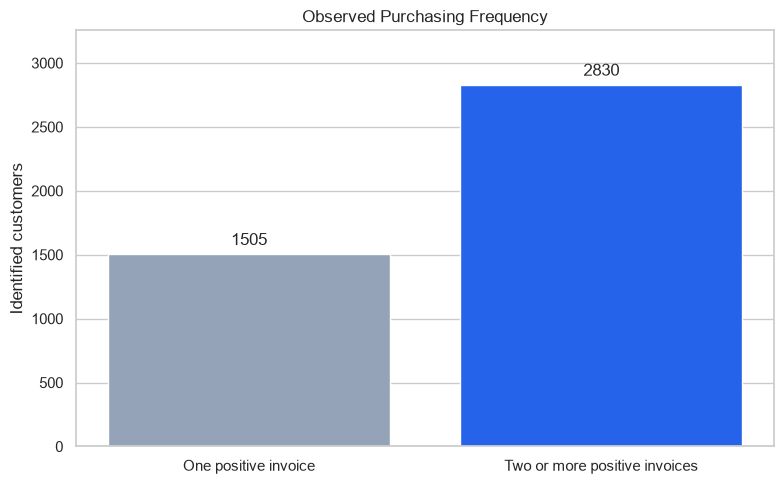

In [31]:
identified_sales = merchandise.loc[
    merchandise["CustomerID"].notna()
].copy()

customer_summary = (
    identified_sales.groupby("CustomerID")
    .agg(
        positive_invoices=("InvoiceNo", "nunique"),
        positive_value=("sales_value", "sum"),
        first_seen=("InvoiceDate", "min"),
        last_seen=("InvoiceDate", "max"),
    )
)

customer_signed = (
    merchandise_ledger
    .dropna(subset=["CustomerID"])
    .groupby("CustomerID")["signed_value"]
    .sum()
)

customer_summary = customer_summary.join(
    customer_signed.rename("signed_value")
)

customer_summary["repeat_purchaser"] = (
    customer_summary["positive_invoices"] >= 2
)

repeat_share = customer_summary["repeat_purchaser"].mean() * 100

print(f"Identified positive purchasers: {len(customer_summary):,}")
print(f"Observed repeat-invoice share: {repeat_share:.2f}%")
print(
    "Customers with positive invoices but nonpositive signed value: "
    f"{customer_summary['signed_value'].le(0).sum():,}"
)

display(
    customer_summary[
        ["positive_invoices", "positive_value", "signed_value"]
    ].describe().round(2)
)

counts = pd.Series({
    "One positive invoice":
        int((customer_summary["positive_invoices"] == 1).sum()),
    "Two or more positive invoices":
        int(customer_summary["repeat_purchaser"].sum()),
})

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    counts.index,
    counts.values,
    color=["#94a3b8", "#2563eb"],
)
ax.bar_label(bars, fmt="%.0f", padding=4)
ax.set_title("Observed Purchasing Frequency")
ax.set_ylabel("Identified customers")
ax.set_ylim(0, counts.max() * 1.15)
ax.grid(axis="x", visible=False)

fig.tight_layout()
fig.savefig(
    FIGURES / "customer_repeat_invoices.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### Customer Findings

65.28% of identified positive purchasers have at least two positive
invoices during the observation period. This is not a retention rate.

Mean signed value (£1,910.71) exceeds the median (£652.07), suggesting
a skewed distribution.

## Customer Value Concentration

Rank customers with positive signed value and calculate the share
contributed by the top 10%. Customers with zero or negative signed
value are reported separately and excluded from this concentration curve.

Customers with positive signed value: 4,325
Top group size (rounded up): 433
Top 10% group's share of positive signed value: 60.05%


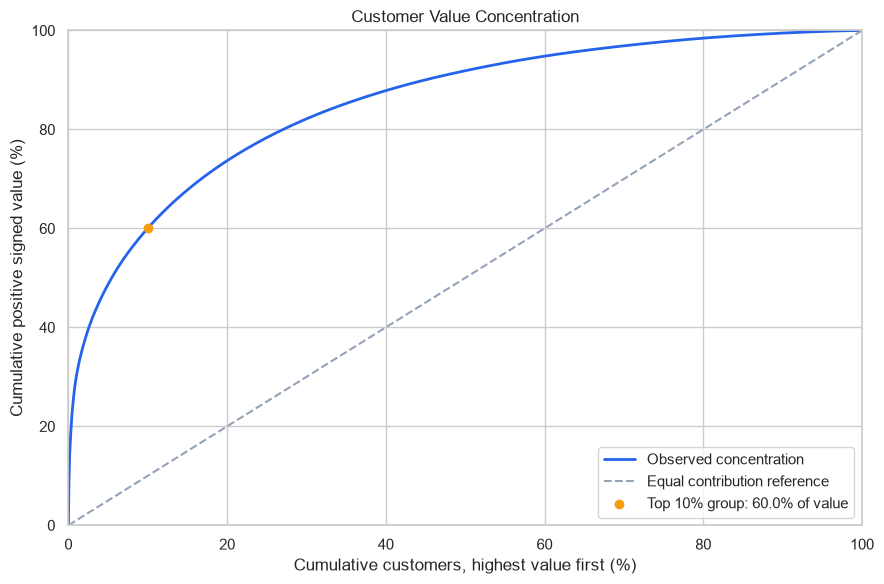

In [32]:
import numpy as np

# Same positive-purchaser population used in customer_summary.
ranked_customers = (
    customer_summary.loc[customer_summary["signed_value"] > 0]
    .sort_values("signed_value", ascending=False)
    .copy()
)

n_customers = len(ranked_customers)
top_n = max(1, int(np.ceil(n_customers * 0.10)))

top_share = (
    ranked_customers.head(top_n)["signed_value"].sum()
    / ranked_customers["signed_value"].sum()
    * 100
)

ranked_customers["customer_share_pct"] = (
    np.arange(1, n_customers + 1) / n_customers * 100
)
ranked_customers["cumulative_value_pct"] = (
    ranked_customers["signed_value"].cumsum()
    / ranked_customers["signed_value"].sum()
    * 100
)

print(f"Customers with positive signed value: {n_customers:,}")
print(f"Top group size (rounded up): {top_n:,}")
print(f"Top 10% group's share of positive signed value: {top_share:.2f}%")

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    np.r_[0, ranked_customers["customer_share_pct"].to_numpy()],
    np.r_[0, ranked_customers["cumulative_value_pct"].to_numpy()],
    color="#2563eb",
    linewidth=2,
    label="Observed concentration",
)
ax.plot(
    [0, 100], [0, 100],
    linestyle="--",
    color="#94a3b8",
    label="Equal contribution reference",
)

ax.scatter(
    top_n / n_customers * 100,
    top_share,
    color="#f59e0b",
    zorder=3,
    label=f"Top 10% group: {top_share:.1f}% of value",
)

ax.set(
    title="Customer Value Concentration",
    xlabel="Cumulative customers, highest value first (%)",
    ylabel="Cumulative positive signed value (%)",
    xlim=(0, 100),
    ylim=(0, 100),
)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURES / "customer_value_concentration.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

## RFM Customer Profiles

- Recency: calendar days since the last positive merchandise invoice.
- Frequency: distinct positive merchandise invoices in the dataset.
- Monetary value: signed merchandise value, including negative entries.
- Reference date: the day after the dataset's last transaction.

Profiles cover identified positive purchasers. Cancelled purchases can
still affect recency and frequency. These are descriptive profiles,
not predictions of loyalty, churn, or future spending.

Customers with nonpositive monetary value remain visible.

Reference date: 2011-12-10


,recency_days,frequency,monetary,positive_value,first_seen,last_seen
CustomerID,,,,,,
12346,326,1,0.00,77183.60,2011-01-18 10:01:00,2011-01-18 10:01:00
12347,3,7,4310.00,4310.00,2010-12-07 14:57:00,2011-12-07 15:52:00
12348,76,4,1437.24,1437.24,2010-12-16 19:09:00,2011-09-25 13:13:00
12349,19,1,1457.55,1457.55,2011-11-21 09:51:00,2011-11-21 09:51:00
12350,311,1,294.40,294.40,2011-02-02 16:01:00,2011-02-02 16:01:00


,recency_days,frequency,monetary
count,4335.00,4335.00,4335.00
mean,93.23,4.25,1910.71
std,100.20,7.65,8291.60
min,1.00,1.00,-796.86
25%,18.00,1.00,298.65
50%,51.00,2.00,652.07
75%,143.00,5.00,1604.08
max,374.00,206.00,278571.62


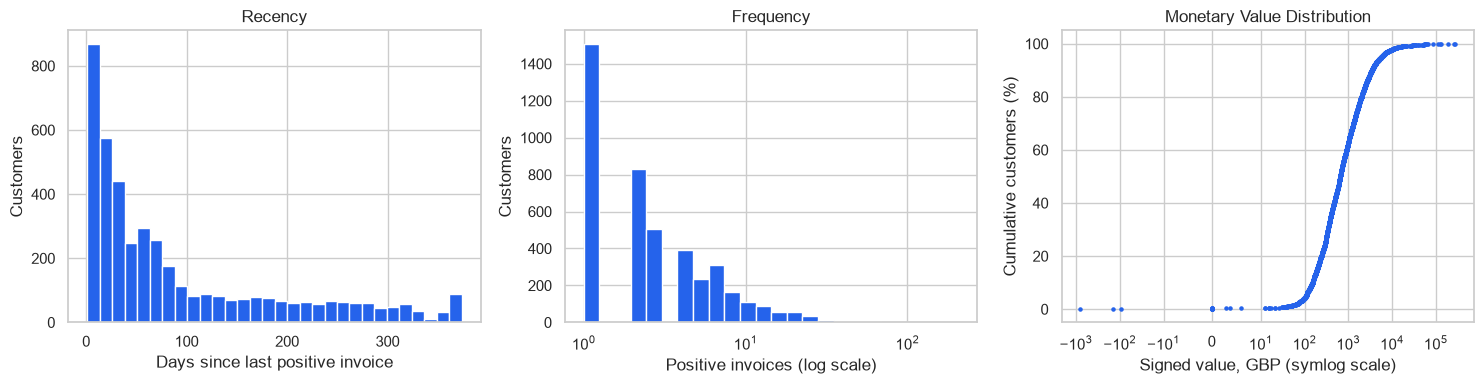

In [33]:
reference_date = (
    df["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

rfm = customer_summary.rename(columns={
    "positive_invoices": "frequency",
    "signed_value": "monetary",
}).copy()

rfm["recency_days"] = (
    reference_date - rfm["last_seen"].dt.normalize()
).dt.days

rfm = rfm[
    [
        "recency_days",
        "frequency",
        "monetary",
        "positive_value",
        "first_seen",
        "last_seen",
    ]
]

assert rfm.index.is_unique
assert rfm["recency_days"].ge(0).all()
assert rfm["frequency"].ge(1).all()
assert rfm["monetary"].notna().all()

print("Reference date:", reference_date.date())
display(rfm.head())
display(
    rfm[["recency_days", "frequency", "monetary"]]
    .describe()
    .round(2)
)

# Keep every customer; logarithmic axes help show skewed distributions.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(rfm["recency_days"], bins=30, color="#2563eb")
axes[0].set(
    title="Recency",
    xlabel="Days since last positive invoice",
    ylabel="Customers",
)

axes[1].hist(
    rfm["frequency"],
    bins=np.geomspace(
        1, rfm["frequency"].max() + 1, 25
    ),
    color="#2563eb",
)
axes[1].set_xscale("log")
axes[1].set(
    title="Frequency",
    xlabel="Positive invoices (log scale)",
    ylabel="Customers",
)

# symlog supports zero and negative monetary values.
axes[2].scatter(
    rfm["monetary"].sort_values().to_numpy(),
    np.arange(1, len(rfm) + 1) / len(rfm) * 100,
    s=5,
    color="#2563eb",
)
axes[2].set_xscale("symlog", linthresh=10)
axes[2].set(
    title="Monetary Value Distribution",
    xlabel="Signed value, GBP (symlog scale)",
    ylabel="Cumulative customers (%)",
)

fig.tight_layout()
fig.savefig(
    FIGURES / "rfm_distributions.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

## Descriptive Customer Groups

Rules are applied in the following order:

1. Nonpositive signed value: monetary value ≤ £0.
2. Recent, frequent, higher value: recency ≤ 30 days, frequency ≥ 5,
   and monetary value at or above the positive-value 75th percentile.
3. Recent repeat: recency ≤ 30 days and frequency ≥ 2.
4. Recent single invoice: recency ≤ 30 days and frequency = 1.
5. No recent invoice: recency > 90 days.
6. Other purchasers: remaining customers.

The 30-day, 90-day, and five-invoice thresholds are illustrative.
Groups are descriptive, not validated predictions of churn or loyalty.
Identical RFM values receive identical group assignments.

Higher-value threshold: £1,610.15


,customers,median_recency_days,median_frequency,median_signed_value,total_signed_value,customer_share_pct
group,,,,,,
No recent invoice,1443,205.0,1.0,338.95,898405.49,33.29
Other purchasers,1255,54.0,2.0,669.38,1544439.42,28.95
Recent repeat,805,15.0,3.0,869.68,829400.52,18.57
"Recent, frequent, higher value",613,9.0,10.0,3650.87,4947655.33,14.14
Recent single invoice,209,19.0,1.0,227.39,64079.30,4.82
Nonpositive signed value,10,184.5,1.0,0.00,-1034.27,0.23


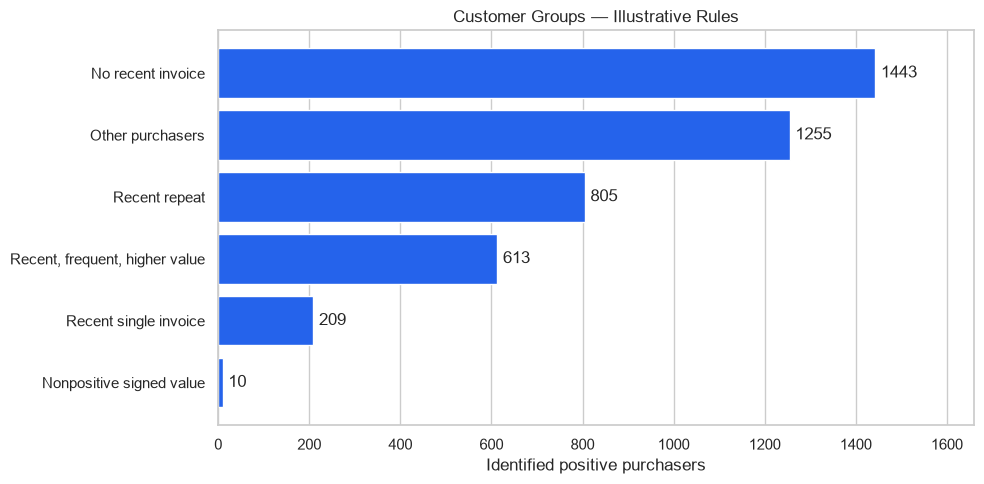

In [34]:
high_value_threshold = rfm.loc[
    rfm["monetary"] > 0, "monetary"
].quantile(0.75)

conditions = [
    rfm["monetary"].le(0),
    (
        rfm["recency_days"].le(30)
        & rfm["frequency"].ge(5)
        & rfm["monetary"].ge(high_value_threshold)
    ),
    rfm["recency_days"].le(30) & rfm["frequency"].ge(2),
    rfm["recency_days"].le(30) & rfm["frequency"].eq(1),
    rfm["recency_days"].gt(90),
]

group_names = [
    "Nonpositive signed value",
    "Recent, frequent, higher value",
    "Recent repeat",
    "Recent single invoice",
    "No recent invoice",
]

rfm["group"] = np.select(
    conditions,
    group_names,
    default="Other purchasers",
)

group_summary = (
    rfm.groupby("group")
    .agg(
        customers=("frequency", "size"),
        median_recency_days=("recency_days", "median"),
        median_frequency=("frequency", "median"),
        median_signed_value=("monetary", "median"),
        total_signed_value=("monetary", "sum"),
    )
    .sort_values("customers", ascending=False)
)

group_summary["customer_share_pct"] = (
    group_summary["customers"] / len(rfm) * 100
)

assert group_summary["customers"].sum() == len(rfm)

print(f"Higher-value threshold: £{high_value_threshold:,.2f}")
display(group_summary.round(2))

plot_data = group_summary.sort_values("customers")

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(
    plot_data.index,
    plot_data["customers"],
    color="#2563eb",
)
ax.bar_label(bars, padding=4, fmt="%.0f")
ax.set(
    title="Customer Groups — Illustrative Rules",
    xlabel="Identified positive purchasers",
)
ax.set_xlim(0, plot_data["customers"].max() * 1.15)
ax.grid(axis="y", visible=False)

fig.tight_layout()
fig.savefig(
    FIGURES / "customer_groups.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

## Weekday and Hourly Invoice Patterns

Count distinct positive merchandise invoices rather than transaction lines.

Weekday averages use every calendar date in the observation period,
including dates without invoices. Hourly counts use timestamps as
recorded; no timezone conversion is applied.

These patterns reflect invoice recording activity and do not establish
customer browsing behavior or business opening hours.

,total_invoices,calendar_days,average_daily_invoices
weekday,,,
Monday,3082,53,58.15
Tuesday,3513,53,66.28
Wednesday,3670,54,67.96
Thursday,4211,54,77.98
Friday,3110,54,57.59
Saturday,0,53,0.00
Sunday,2203,53,41.57


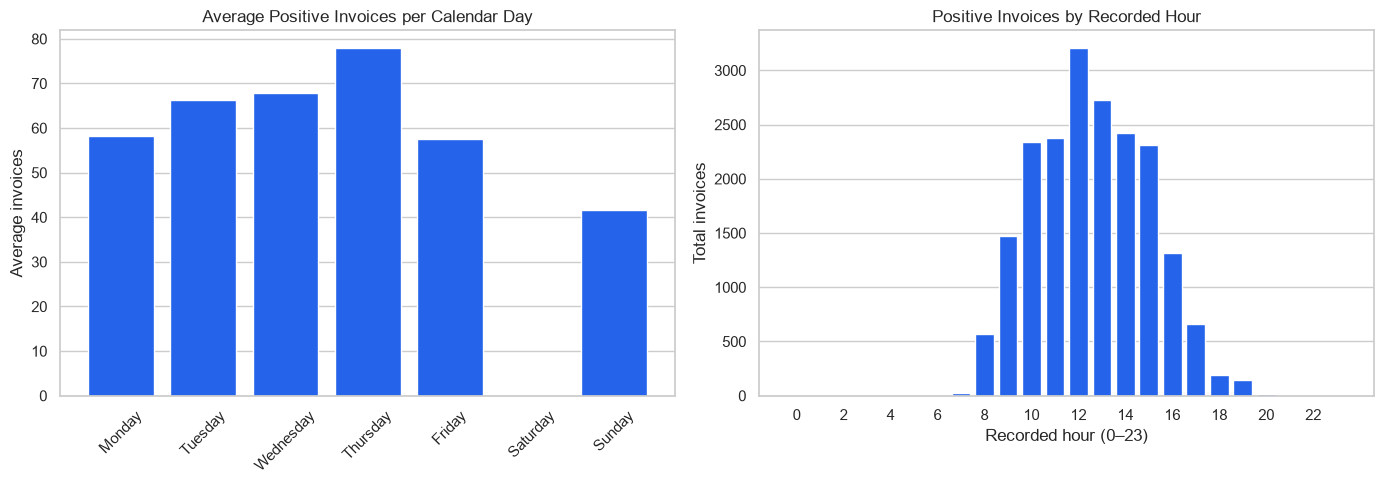

Highest average weekday: Thursday
Highest invoice-count hour: 12:00


In [35]:
# Assign each positive merchandise invoice its earliest recorded time.
invoice_times = (
    merchandise.groupby("InvoiceNo")["InvoiceDate"]
    .min()
    .to_frame("invoice_time")
)

invoice_times["date"] = invoice_times["invoice_time"].dt.normalize()
invoice_times["hour"] = invoice_times["invoice_time"].dt.hour

calendar = pd.date_range(
    df["InvoiceDate"].min().normalize(),
    df["InvoiceDate"].max().normalize(),
    freq="D",
)

daily_counts = (
    invoice_times.groupby("date").size()
    .reindex(calendar, fill_value=0)
    .rename("invoices")
    .to_frame()
)

daily_counts["weekday"] = daily_counts.index.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday",
]

weekday_summary = (
    daily_counts.groupby("weekday")
    .agg(
        total_invoices=("invoices", "sum"),
        calendar_days=("invoices", "size"),
        average_daily_invoices=("invoices", "mean"),
    )
    .reindex(weekday_order)
)

hourly_counts = (
    invoice_times.groupby("hour").size()
    .reindex(range(24), fill_value=0)
)

display(weekday_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    weekday_summary.index,
    weekday_summary["average_daily_invoices"],
    color="#2563eb",
)
axes[0].set(
    title="Average Positive Invoices per Calendar Day",
    ylabel="Average invoices",
)
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(
    hourly_counts.index,
    hourly_counts.values,
    color="#2563eb",
)
axes[1].set(
    title="Positive Invoices by Recorded Hour",
    xlabel="Recorded hour (0–23)",
    ylabel="Total invoices",
)
axes[1].set_xticks(range(0, 24, 2))

for ax in axes:
    ax.grid(axis="x", visible=False)

fig.tight_layout()
fig.savefig(
    FIGURES / "weekday_hour_patterns.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print(
    "Highest average weekday:",
    weekday_summary["average_daily_invoices"].idxmax(),
)
print(f"Highest invoice-count hour: {hourly_counts.idxmax():02d}:00")

In [36]:
PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

outputs = {
    "data_quality.csv": quality_report,
    "monthly_positive_transactions.csv": monthly,
    "country_positive_transactions.csv": country_summary,
    "product_value_comparison.csv": product_comparison,
    "customer_rfm.csv": rfm,
    "customer_groups.csv": group_summary,
    "weekday_invoices.csv": weekday_summary,
    "hourly_invoices.csv": hourly_counts.rename("invoices").to_frame(),
    "duplicate_sensitivity.csv": comparison,
}

for filename, table in outputs.items():
    table.to_csv(PROCESSED / filename, index=True)

print(f"Saved {len(outputs)} analysis tables to:")
print(PROCESSED)

Saved 9 analysis tables to:
/Users/rashmidragon/Desktop/ecommerce-customer-eda/data/processed


# E-commerce Customer Behavior EDA

An exploratory data analysis of transaction and customer patterns using
the UCI Online Retail dataset. The project examines data quality,
transaction trends, product value, repeat invoices, and customer profiles.

## Dataset

The [UCI Online Retail dataset](https://archive.ics.uci.edu/dataset/352/online+retail)
contains 541,909 transaction lines from a UK-based retailer between
December 1, 2010 and December 9, 2011. Amounts are in British pounds.

**Source:** Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine
Learning Repository. https://doi.org/10.24432/C5BW33

**License:** Creative Commons Attribution 4.0 International (CC BY 4.0).

The raw workbook is not stored in this repository. Download the dataset
from UCI, extract it, and place `Online Retail.xlsx` in `data/raw/`.

## Analysis

- Data quality, missing customer IDs, and potential duplicates
- Monthly and geographic positive transaction value
- Product rankings using positive and signed transaction value
- Large transaction and cancellation investigation
- Repeat invoices and customer value concentration
- Descriptive recency, frequency, and monetary value profiles
- Weekday and hourly invoice patterns

## Selected Findings

- November 2011 had the highest full-month positive transaction value:
  **£1,509,496.33**. December 2011 is incomplete.
- The UK represented **84.61%** of positive transaction value.
- Among 4,335 identified positive merchandise purchasers, **65.28%**
  had at least two positive invoices during the observation period.
- The top 433 customers contributed **60.05%** of signed value among
  4,325 customers with positive signed value in the purchaser population.
- Thursday averaged **77.98** positive merchandise invoices per calendar
  day. The busiest recorded hour was **12:00–12:59**.

These are descriptive results for this retailer and observation period.

## Visualizations

### Monthly positive transaction value

![Monthly positive transaction value](reports/figures/monthly_sales.png)

### Customer value concentration

![Customer value concentration](reports/figures/customer_value_concentration.png)

### Customer groups

![Illustrative customer groups](reports/figures/customer_groups.png)

## Methods and Limitations

- Positive transaction value includes non-cancellation lines with
  positive quantity and price. It includes charges and original
  entries that may subsequently be cancelled.
- Signed merchandise value includes positive and negative quantities
  at positive prices. A provisional list excludes observed fee and
  accounting codes; it may not identify every non-merchandise entry.
- Customer analyses exclude missing CustomerIDs. CustomerID is missing
  in 24.93% of original rows.
- Potential duplicate lines are retained. Excluding them reduces
  positive transaction value by approximately 0.23%.
- Repeat-invoice share is not a retention rate. Positive invoices may
  subsequently be cancelled, and customers have different observation
  lengths.
- RFM groups use illustrative thresholds. They are not validated
  predictions of churn or loyalty.
- Invoice timestamps describe recorded activity; their timezone has
  not been converted.
- The analysis does not measure profit or establish causality.

## Project Structure

```text
ecommerce-customer-eda/
├── data/
│   ├── raw/                 # Place the UCI workbook here
│   └── processed/           # Exported analysis tables
├── notebooks/
│   └── 01_retail_eda.ipynb
├── reports/
│   └── figures/
├── .gitignore
├── requirements.txt
└── README.md
```

## Run Locally

1. Clone the repository and enter the project folder.
2. Download and extract the UCI dataset. Place `Online Retail.xlsx`
   in `data/raw/`.
3. Create and activate a Python environment:

   ```bash
   python3 -m venv .venv
   source .venv/bin/activate
   ```

4. Install the dependencies:

   ```bash
   python -m pip install -r requirements.txt
   ```

5. Open `notebooks/01_retail_eda.ipynb` in VS Code, select the `.venv`
   kernel, and choose **Run All**.

The notebook creates the analysis tables and figures in `data/processed/`
and `reports/figures/`.

## Author

Rashmi Thimmaraju  
[GitHub](https://github.com/Rashmioffcialpage)

## Conclusions

### Key Findings

- November 2011 had the highest full-month positive transaction value:
  £1,509,496.33. December 2011 is incomplete.
- The UK contributed 84.61% of positive transaction value.
- Large reversed transactions materially changed product rankings.
  Stock code 23843 had £168,469.60 in positive value but £0 signed value.
- Among identified positive merchandise purchasers, 65.28% had
  two or more positive invoices during the observation period.
- The top 433 customers contributed 60.05% of signed value among
  the 4,325 positive-value customers in the purchaser population.
- Thursday had the highest average positive merchandise invoice count
  per calendar day (77.98). The busiest recorded hour was 12:00–12:59.

### Business Questions to Investigate

- Review dependence on high-value customers and investigate their needs.
- Validate invoice-recording patterns against operational schedules
  before changing staffing or campaign timing.
- Investigate reversals and accounting entries before using transaction
  totals for product or customer decisions.
- Test customer-group outreach with controlled experiments before
  claiming an effect on repeat purchasing.

### Limitations

- This historical dataset describes one retailer.
- CustomerID is missing in 24.93% of original rows.
- Duplicate candidates are retained; excluding them reduces positive
  transaction value by 0.23%.
- The non-merchandise exclusion list is provisional.
- Positive transaction totals include charges and subsequently
  cancelled entries; signed merchandise totals use a different scope.
- Recency and frequency use positive invoices, including ones that may
  later be cancelled.
- Customer observation periods differ.
- Customer groups use illustrative thresholds.
- The analysis does not measure profit, establish causality, or predict churn.